In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [39]:
import pandas as pd

columns = [
    'fLength', 'fWidth', 'fSize', 'fConc', 'fConc1',
    'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist',
    'class'
]

df = pd.read_csv('/content/magic04.data', names=columns)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (19020, 11)


,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [40]:
# Check dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  object 
dtypes: float64(10), object(1)
memory usage: 1.6+ MB


In [41]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
fLength     0
fWidth      0
fSize       0
fConc       0
fConc1      0
fAsym       0
fM3Long     0
fM3Trans    0
fAlpha      0
fDist       0
class       0
dtype: int64


In [42]:
# Separate features and target

X = df.drop('class', axis=1)
y = df['class']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (19020, 10)
Target Shape: (19020,)


In [43]:
# Convert class labels into numbers

y = y.map({'g': 1, 'h': 0})

print(y.value_counts())

class
1    12332
0     6688
Name: count, dtype: int64


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (15216, 10)
Testing data shape: (3804, 10)
Training target shape: (15216,)
Testing target shape: (3804,)


In [45]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (15216, 10)
Scaled testing data shape: (3804, 10)


In [46]:
from sklearn.neighbors import KNeighborsClassifier

print("KNN imported successfully!")

KNN imported successfully!


In [47]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [48]:
y_pred = knn_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1]


In [49]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", knn_accuracy * 100, "%")

KNN Model Accuracy: 83.4384858044164 %


In [50]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 879  465]
 [ 165 2295]]


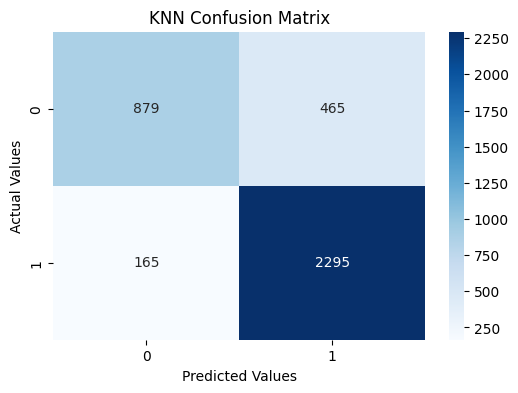

In [51]:
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("KNN Confusion Matrix")

plt.show()

In [52]:
from sklearn.naive_bayes import GaussianNB

print("Naive Bayes imported successfully!")

Naive Bayes imported successfully!


In [53]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_predictions = nb_model.predict(X_test_scaled)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [54]:
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:", nb_accuracy * 100, "%")

Naive Bayes Accuracy: 72.68664563617246 %


In [55]:
nb_cm = confusion_matrix(y_test, nb_predictions)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[ 508  836]
 [ 203 2257]]


In [56]:
print("Naive Bayes Classification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.38      0.49      1344
           1       0.73      0.92      0.81      2460

    accuracy                           0.73      3804
   macro avg       0.72      0.65      0.65      3804
weighted avg       0.72      0.73      0.70      3804



In [57]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")

Logistic Regression imported successfully!


In [58]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [59]:
lr_predictions = lr_model.predict(X_test_scaled)

print("Predictions:")
print(lr_predictions[:20])

Predictions:
[1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1]


In [60]:
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 79.31125131440588 %


In [61]:
lr_cm = confusion_matrix(y_test, lr_predictions)

print("Logistic Regression Confusion Matrix:")
print(lr_cm)

Logistic Regression Confusion Matrix:
[[ 812  532]
 [ 255 2205]]


In [62]:
print("Logistic Regression Classification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.60      0.67      1344
           1       0.81      0.90      0.85      2460

    accuracy                           0.79      3804
   macro avg       0.78      0.75      0.76      3804
weighted avg       0.79      0.79      0.79      3804



In [63]:
from sklearn.svm import SVC

print("SVM imported successfully!")

SVM imported successfully!


In [64]:
svm_model = SVC()

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [65]:
svm_predictions = svm_model.predict(X_test_scaled)

print("SVM predictions:")
print(svm_predictions[:20])

SVM predictions:
[0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1]


In [66]:
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 87.11882229232387 %


In [67]:
svm_cm = confusion_matrix(y_test, svm_predictions)

print("SVM Confusion Matrix:")
print(svm_cm)

SVM Confusion Matrix:
[[ 957  387]
 [ 103 2357]]


In [68]:
print("SVM Classification Report:")
print(classification_report(y_test, svm_predictions))

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1344
           1       0.86      0.96      0.91      2460

    accuracy                           0.87      3804
   macro avg       0.88      0.84      0.85      3804
weighted avg       0.87      0.87      0.87      3804



In [69]:
# Install TensorFlow (if required)
!pip install tensorflow

# Import libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("TensorFlow imported successfully!")

TensorFlow version: 2.21.0
TensorFlow imported successfully!


In [70]:
# Build Neural Network
nn_model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

# Compile model
nn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
nn_model.summary()

# Train model
history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate model
nn_loss, nn_accuracy = nn_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("\nNeural Network Test Accuracy:", nn_accuracy * 100, "%")

# Make predictions
nn_predictions = (nn_model.predict(X_test_scaled) > 0.5).astype(int).flatten()

# Confusion Matrix
nn_cm = confusion_matrix(y_test, nn_predictions)
print("\nNeural Network Confusion Matrix:")
print(nn_cm)

# Classification Report
print("\nNeural Network Classification Report:")
print(classification_report(y_test, nn_predictions))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8067 - loss: 0.4283 - val_accuracy: 0.8476 - val_loss: 0.3692
Epoch 2/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8537 - loss: 0.3512 - val_accuracy: 0.8578 - val_loss: 0.3486
Epoch 3/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8607 - loss: 0.3357 - val_accuracy: 0.8574 - val_loss: 0.3379
Epoch 4/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8645 - loss: 0.3260 - val_accuracy: 0.8633 - val_loss: 0.3270
Epoch 5/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8672 - loss: 0.3210 - val_accuracy: 0.8627 - val_loss: 0.3266
Epoch 6/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8694 - loss: 0.3166 - val_accuracy: 0.8689 - val_loss: 0.3261
Epoch 7/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8703 - loss: 0.3122 - val_accuracy: 0.8624 - val_loss: 0.3262
Epoch 8/20
381/381 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8698 - loss: 0.3100 - val_accuracy: 0.

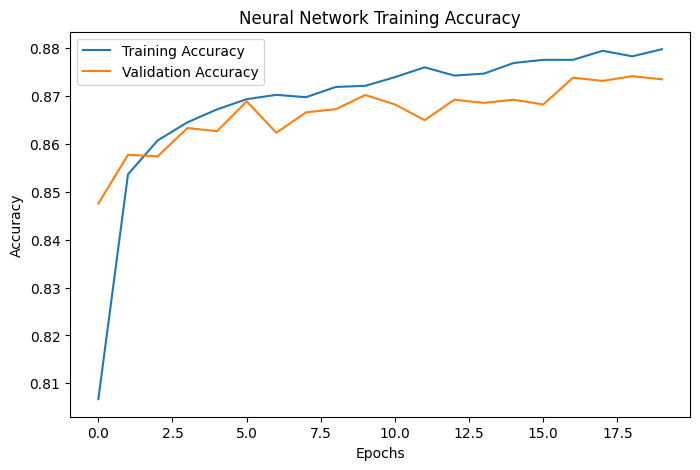

In [71]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Neural Network Training Accuracy')
plt.legend()
plt.show()

In [72]:
# Compare all classification models

model_names = [
    'KNN',
    'Naive Bayes',
    'Logistic Regression',
    'SVM',
    'Neural Network'
]

model_accuracies = [
    knn_accuracy,
    nb_accuracy,
    lr_accuracy,
    svm_accuracy,
    nn_accuracy
]

comparison_df = pd.DataFrame({
    'Model': model_names,
    'Accuracy (%)': [acc * 100 for acc in model_accuracies]
})

print("Classification Model Comparison:")
display(comparison_df.sort_values(
    by='Accuracy (%)',
    ascending=False
))

Classification Model Comparison:


,Model,Accuracy (%)
4,Neural Network,87.250262
3,SVM,87.118822
0,KNN,83.438486
2,Logistic Regression,79.311251
1,Naive Bayes,72.686646


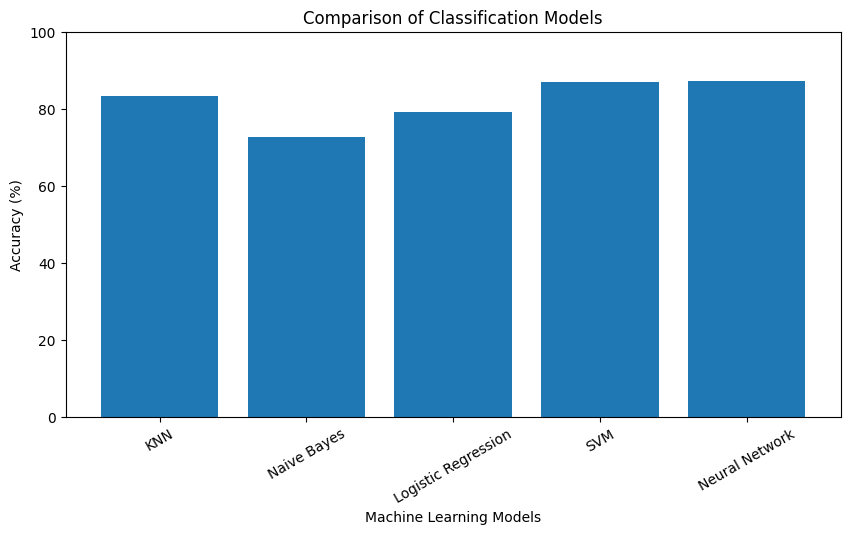

In [73]:
plt.figure(figsize=(10, 5))

plt.bar(model_names, [acc * 100 for acc in model_accuracies])

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Classification Models")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

## Conclusion

In this project, we implemented five machine learning classification algorithms using the MAGIC Gamma Telescope dataset.

The algorithms used were:

1. K-Nearest Neighbors (KNN)
2. Naive Bayes
3. Logistic Regression
4. Support Vector Machine (SVM)
5. Artificial Neural Network using TensorFlow

The dataset was explored, cleaned, divided into training and testing sets, and standardized before model training.

We evaluated the models using accuracy, confusion matrices, precision, recall, and F1-score.

Finally, we compared the performance of all five models to identify which algorithm performed best on the test dataset.

This project helped us understand the practical implementation and evaluation of supervised machine learning classification algorithms.
